In [3]:
import Pkg
Pkg.activate("..")
Pkg.instantiate()

using CSV
using DataFrames
using Plots

  Activating project at `d:\OneDrive\Desktop\HCMUS-CNTT(TCTA)\NAM-BA-(2026-2027)\HK1\DM\projects\fim\Group 7`


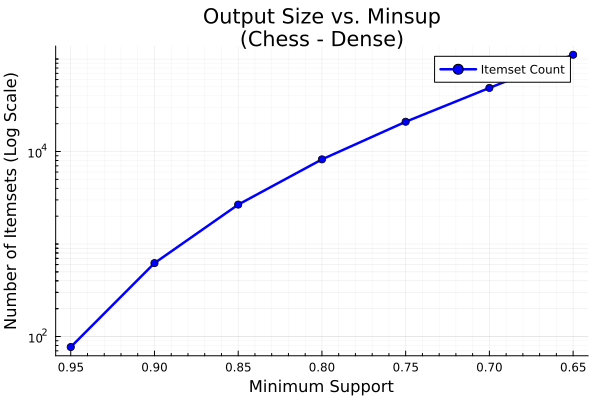

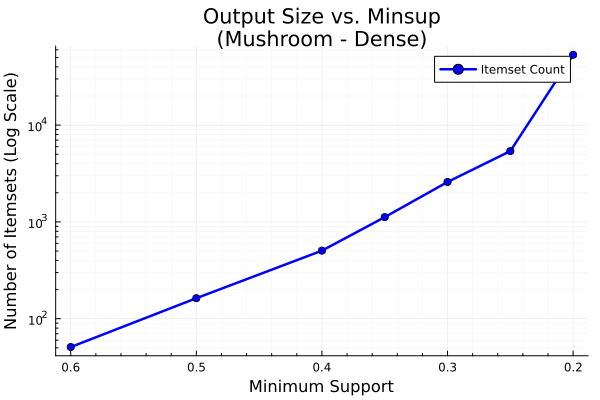

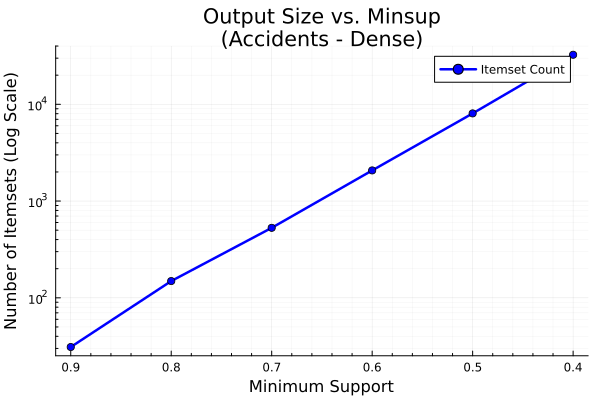

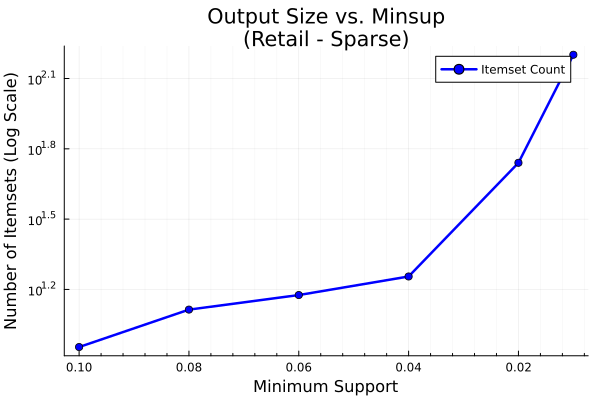

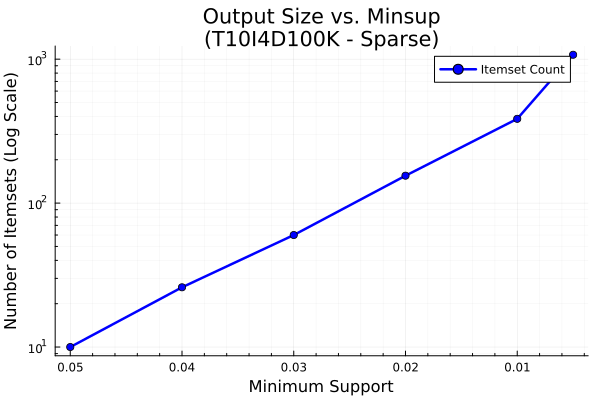

In [10]:
df_counts = CSV.read("../data/results/exp3_itemset_count/exp3_itemset_counts.csv", DataFrame)
datasets = unique(df_counts.Dataset)

for dataset in datasets
    data = filter(row -> row.Dataset == dataset, df_counts)
    ds_type = first(data.Type)
    
    p = plot(data.Minsup, data.Itemset_Count, 
        label="Itemset Count", 
        marker=:circle, 
        lw=2.5, 
        color=:blue
    )
    
    plot!(p, 
        xflip = true,
        yscale = :log10,
        title = "Output Size vs. Minsup\n($(uppercasefirst(dataset)) - $(ds_type))",
        xlabel = "Minimum Support",
        ylabel = "Number of Itemsets (Log Scale)",
        legend = :topright,
        grid = true,
        minorgrid = true
    )
    
    display(p)
    savefig(p, "../data/results/exp3_itemset_count/plot_count_$(dataset).png")
end